In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
dev_df = pd.read_csv("dev.csv")

print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)
print("Dev Shape:", dev_df.shape)

print("\nTrain Columns:")
print(train_df.columns.tolist())

print("\nFirst 5 Rows:")
display(train_df.head())

Train Shape: (10003, 3)
Test Shape: (3080, 3)
Dev Shape: (3080, 3)

Train Columns:
['text', 'label', 'label_text']

First 5 Rows:


,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival


In [6]:
print("TRAIN DATA INFORMATION")
print("=" * 50)

train_df.info()

print("\n\nMissing Values:")
print(train_df.isnull().sum())

print("\n\nDuplicate Rows:")
print(train_df.duplicated().sum())

print("\n\nNumber of Categories:")
print(train_df["label_text"].nunique())

print("\n\nNumber of Labels:")
print(train_df["label"].nunique())

TRAIN DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   text        10003 non-null  object
 1   label       10003 non-null  int64 
 2   label_text  10003 non-null  object
dtypes: int64(1), object(2)
memory usage: 234.6+ KB


Missing Values:
text          0
label         0
label_text    0
dtype: int64


Duplicate Rows:
0


Number of Categories:
77


Number of Labels:
77


In [7]:
train_test_overlap = len(set(train_df["text"]) & set(test_df["text"]))
train_dev_overlap = len(set(train_df["text"]) & set(dev_df["text"]))
test_dev_overlap = len(set(test_df["text"]) & set(dev_df["text"]))

print("Train-Test Overlap:", train_test_overlap)
print("Train-Dev Overlap:", train_dev_overlap)
print("Test-Dev Overlap:", test_dev_overlap)

Train-Test Overlap: 0
Train-Dev Overlap: 0
Test-Dev Overlap: 3080


In [8]:
display(train_df[["text", "label_text"]].sample(10, random_state=42))

,text,label_text
6883,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer
5573,Why am I getting declines when trying to make ...,declined_transfer
576,What is the $1 transaction on my account?,extra_charge_on_statement
6832,It looks like my card payment was sent back.,reverted_card_payment?
7111,Why am I unable to transfer money when I was a...,beneficiary_not_allowed
439,What if there is an error on the exchange rate?,card_payment_wrong_exchange_rate


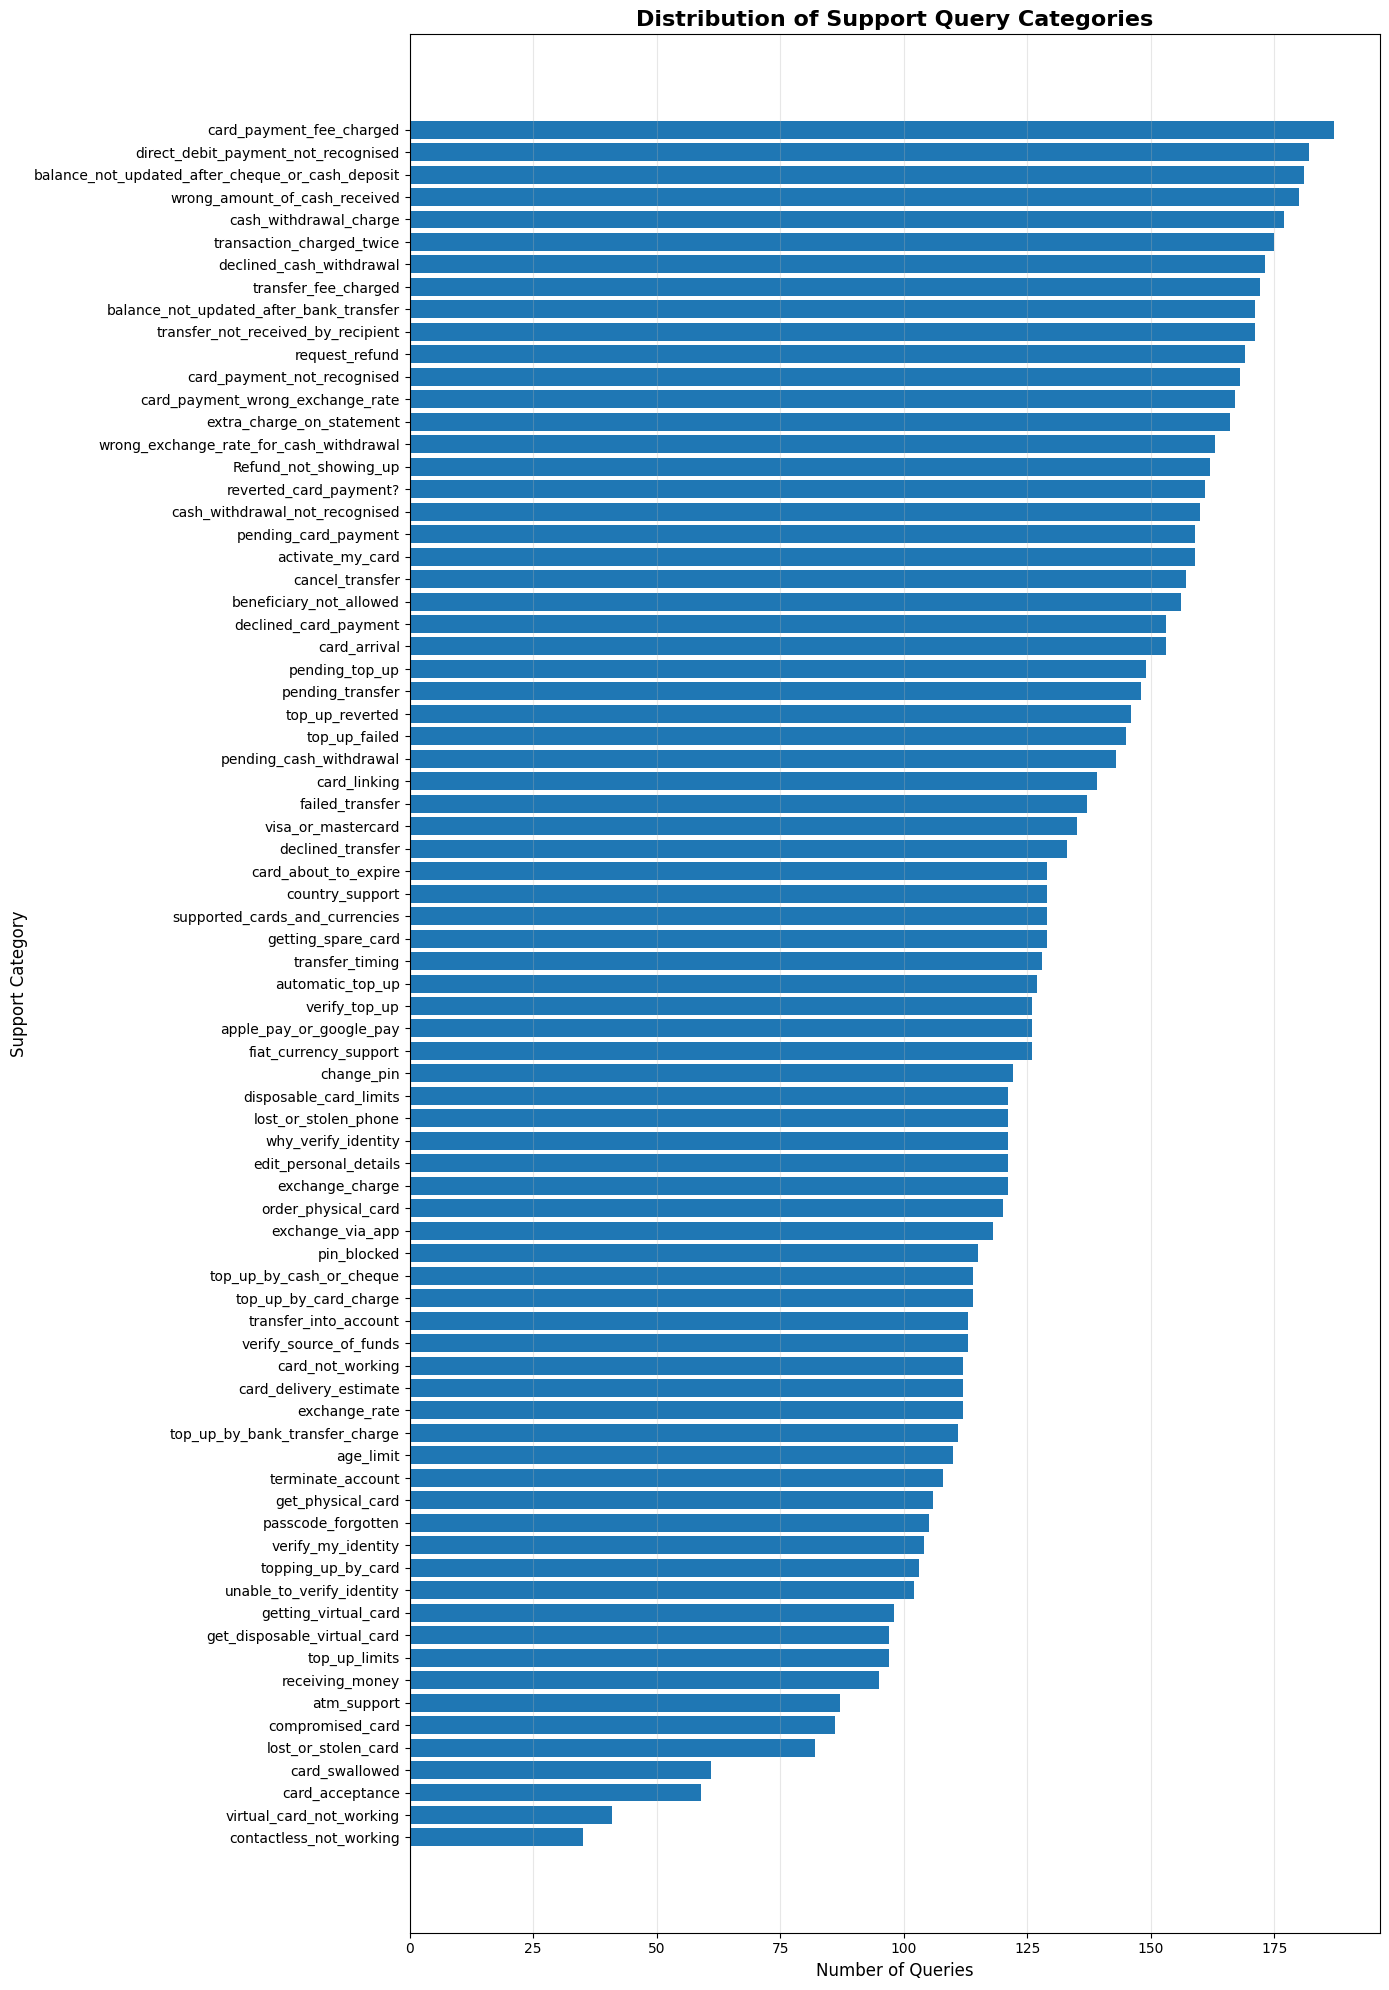

In [9]:
plt.figure(figsize=(14, 20))

category_counts = train_df["label_text"].value_counts().sort_values(ascending=True)

plt.barh(
    category_counts.index,
    category_counts.values
)

plt.title(
    "Distribution of Support Query Categories",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Queries", fontsize=12)
plt.ylabel("Support Category", fontsize=12)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
train_df["word_count"] = train_df["text"].apply(
    lambda x: len(str(x).split())
)

print(train_df["word_count"].describe())

count    10003.000000
mean        11.949415
std          7.891577
min          2.000000
25%          7.000000
50%         10.000000
75%         13.000000
max         79.000000
Name: word_count, dtype: float64


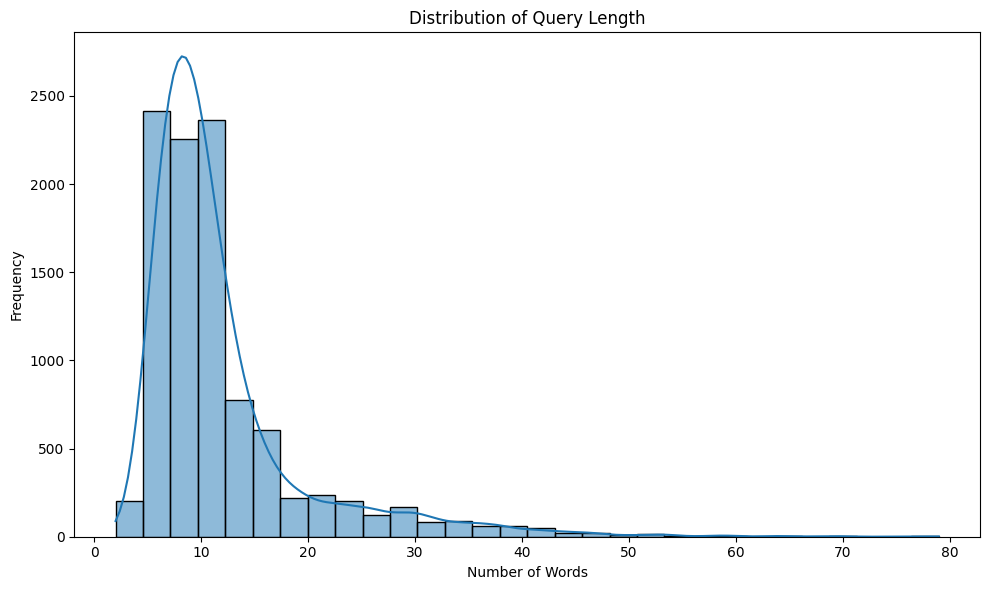

In [11]:
plt.figure(figsize=(10, 6))

sns.histplot(
    train_df["word_count"],
    bins=30,
    kde=True
)

plt.title("Distribution of Query Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

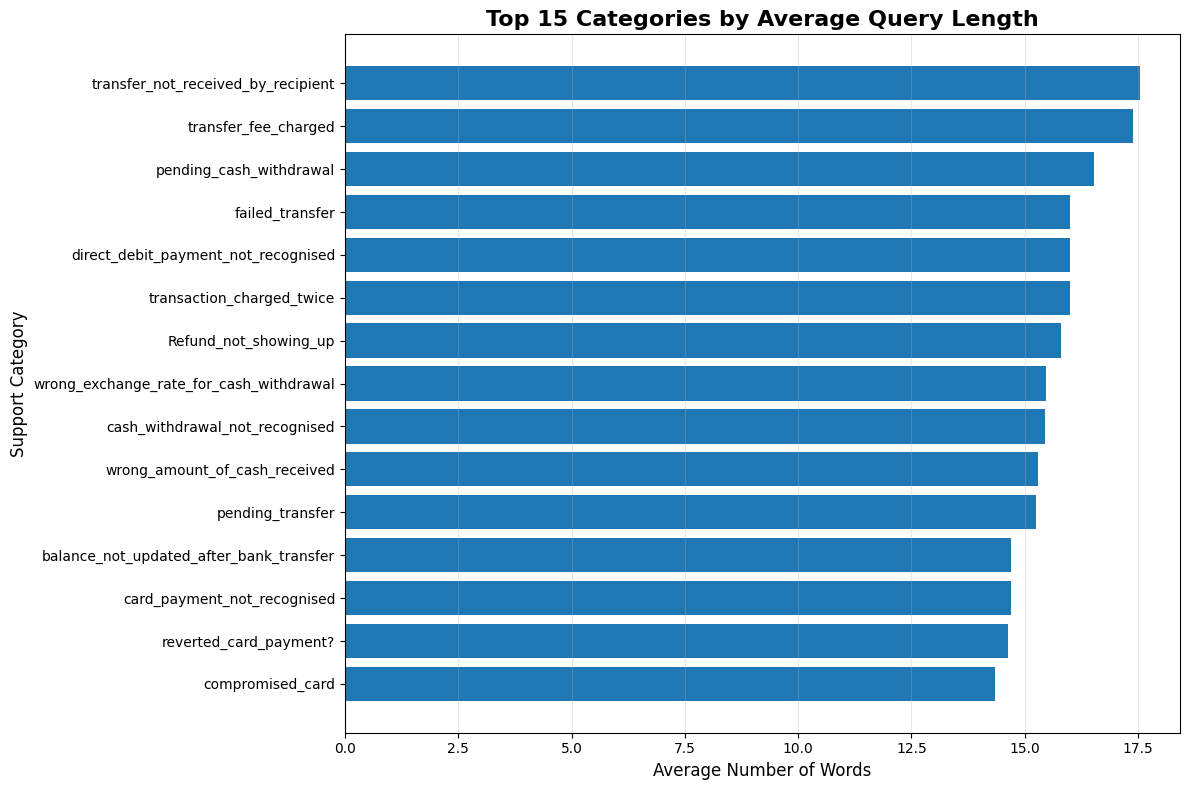

In [12]:
# Average Query Length - Top 15 Categories

avg_length = (
    train_df.groupby("label_text")["word_count"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 8))

plt.barh(
    avg_length.index,
    avg_length.values
)

plt.title(
    "Top 15 Categories by Average Query Length",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Average Number of Words",
    fontsize=12
)

plt.ylabel(
    "Support Category",
    fontsize=12
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [13]:
def clean_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

display(train_df[["text", "clean_text"]].head(10))

,text,clean_text
0,I am still waiting on my card?,i am still waiting on my card
1,What can I do if my card still hasn't arrived ...,what can i do if my card still hasn t arrived ...
2,I have been waiting over a week. Is the card s...,i have been waiting over a week is the card st...
3,Can I track my card while it is in the process...,can i track my card while it is in the process...
4,"How do I know if I will get my card, or if it ...",how do i know if i will get my card or if it i...
5,When did you send me my new card?,when did you send me my new card
6,Do you have info about the card on delivery?,do you have info about the card on delivery
7,What do I do if I still have not received my n...,what do i do if i still have not received my n...
8,Does the package with my card have tracking?,does the package with my card have tracking
9,I ordered my card but it still isn't here,i ordered my card but it still isn t here


In [14]:
X = train_df["clean_text"]
y = train_df["label_text"]

X_test = test_df["clean_text"]
y_test = test_df["label_text"]

print("Training Samples:", len(X))
print("Testing Samples:", len(X_test))
print("Number of Classes:", y.nunique())

Training Samples: 10003
Testing Samples: 3080
Number of Classes: 77


In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", len(X_train))
print("Validation Data:", len(X_val))
print("Test Data:", len(X_test))

Training Data: 8002
Validation Data: 2001
Test Data: 3080


In [16]:
tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

print("TF-IDF Training Shape:", X_train_tfidf.shape)
print("TF-IDF Validation Shape:", X_val_tfidf.shape)

TF-IDF Training Shape: (8002, 20794)
TF-IDF Validation Shape: (2001, 20794)


In [17]:
nb_model = MultinomialNB(alpha=0.1)

nb_model.fit(
    X_train_tfidf,
    y_train
)

nb_pred = nb_model.predict(X_val_tfidf)

nb_accuracy = accuracy_score(y_val, nb_pred)
nb_precision = precision_score(y_val, nb_pred, average="weighted")
nb_recall = recall_score(y_val, nb_pred, average="weighted")
nb_f1 = f1_score(y_val, nb_pred, average="weighted")

print("Naive Bayes Results")
print("=" * 40)
print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))

Naive Bayes Results
Accuracy : 0.8531
Precision: 0.8594
Recall   : 0.8531
F1 Score : 0.8514


In [18]:
lr_model = LogisticRegression(
    max_iter=2000,
    C=2.0,
    random_state=42
)

lr_model.fit(
    X_train_tfidf,
    y_train
)

lr_pred = lr_model.predict(X_val_tfidf)

lr_accuracy = accuracy_score(y_val, lr_pred)
lr_precision = precision_score(y_val, lr_pred, average="weighted")
lr_recall = recall_score(y_val, lr_pred, average="weighted")
lr_f1 = f1_score(y_val, lr_pred, average="weighted")

print("Logistic Regression Results")
print("=" * 40)
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))

Logistic Regression Results
Accuracy : 0.8636
Precision: 0.8699
Recall   : 0.8636
F1 Score : 0.8636


In [19]:
svm_model = LinearSVC(
    C=1.0,
    random_state=42
)

svm_model.fit(
    X_train_tfidf,
    y_train
)

svm_pred = svm_model.predict(X_val_tfidf)

svm_accuracy = accuracy_score(y_val, svm_pred)
svm_precision = precision_score(y_val, svm_pred, average="weighted")
svm_recall = recall_score(y_val, svm_pred, average="weighted")
svm_f1 = f1_score(y_val, svm_pred, average="weighted")

print("Linear SVM Results")
print("=" * 40)
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1 Score :", round(svm_f1, 4))

Linear SVM Results
Accuracy : 0.8831
Precision: 0.888
Recall   : 0.8831
F1 Score : 0.8835


In [20]:
results = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression",
        "Linear SVM"
    ],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy
    ],
    "Precision": [
        nb_precision,
        lr_precision,
        svm_precision
    ],
    "Recall": [
        nb_recall,
        lr_recall,
        svm_recall
    ],
    "F1 Score": [
        nb_f1,
        lr_f1,
        svm_f1
    ]
})

results = results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(
    results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.8831,0.8880,0.8831,0.8835
1,Logistic Regression,0.8636,0.8699,0.8636,0.8636
2,Multinomial Naive Bayes,0.8531,0.8594,0.8531,0.8514


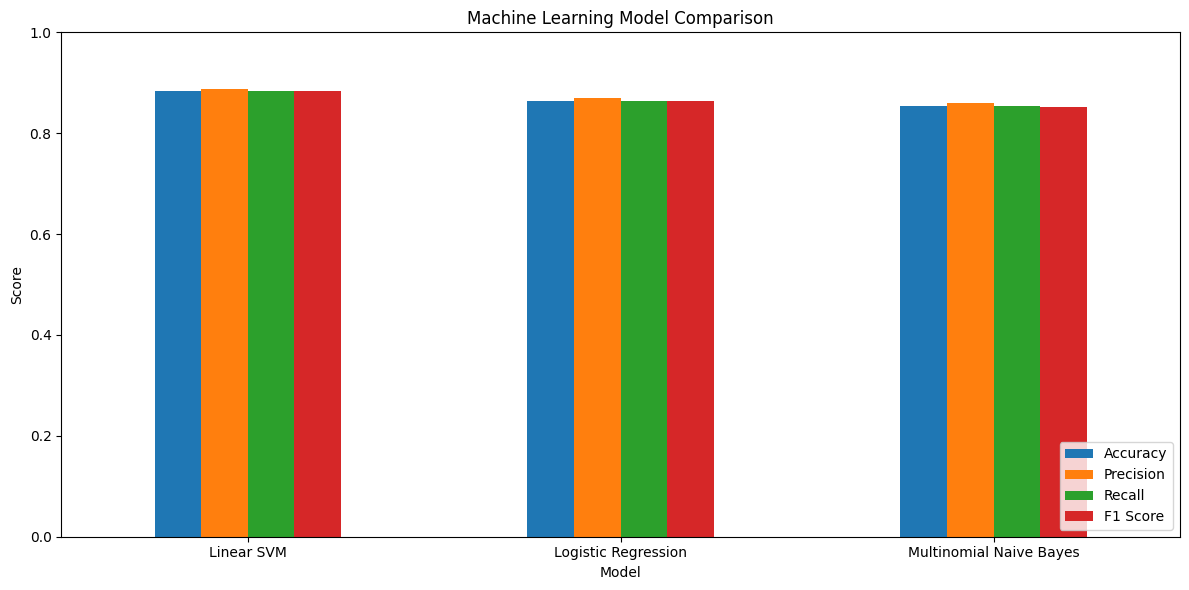

In [21]:
results_plot = results.set_index("Model")

results_plot[[
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [22]:
best_model_name = results.iloc[0]["Model"]

print("Best Model Based on Validation F1 Score:")
print(best_model_name)

Best Model Based on Validation F1 Score:
Linear SVM


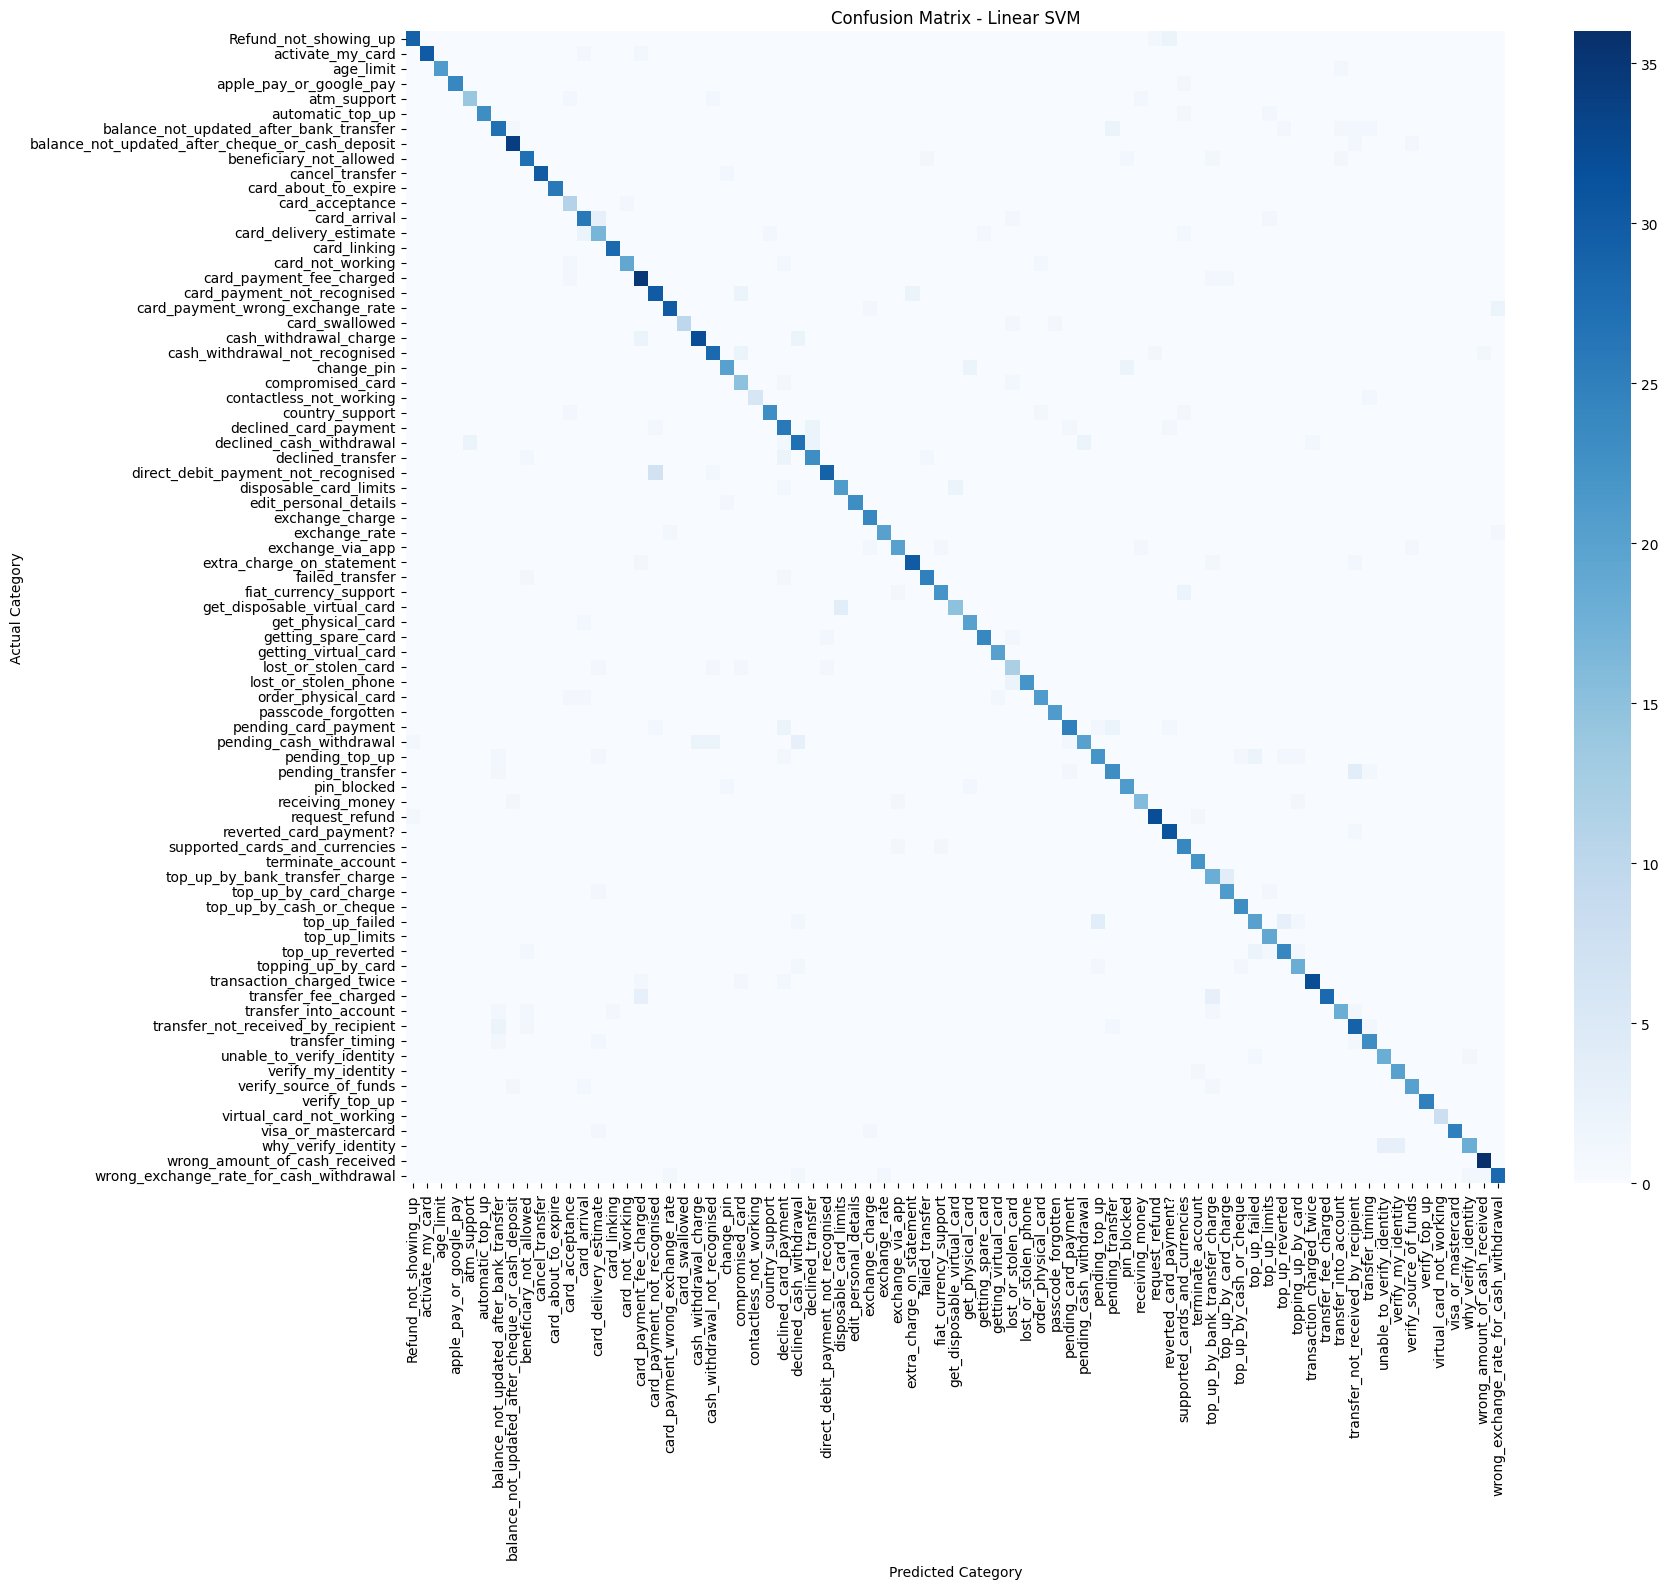

In [23]:
if best_model_name == "Multinomial Naive Bayes":
    best_model = nb_model
    best_pred = nb_pred

elif best_model_name == "Logistic Regression":
    best_model = lr_model
    best_pred = lr_pred

else:
    best_model = svm_model
    best_pred = svm_pred


cm = confusion_matrix(
    y_val,
    best_pred,
    labels=sorted(y.unique())
)

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

In [24]:
print(f"Classification Report - {best_model_name}")
print("=" * 80)

print(
    classification_report(
        y_val,
        best_pred,
        zero_division=0
    )
)

Classification Report - Linear SVM
                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.94      0.91      0.92        32
                                activate_my_card       1.00      0.94      0.97        32
                                       age_limit       1.00      0.95      0.98        22
                         apple_pay_or_google_pay       1.00      0.96      0.98        25
                                     atm_support       0.88      0.82      0.85        17
                                automatic_top_up       1.00      0.92      0.96        25
         balance_not_updated_after_bank_transfer       0.82      0.79      0.81        34
balance_not_updated_after_cheque_or_cash_deposit       0.92      0.94      0.93        36
                         beneficiary_not_allowed       0.84      0.87      0.86        31
                                 cancel_transfer       1.00     

In [25]:
error_df = pd.DataFrame({
    "text": X_val.values,
    "actual": y_val.values,
    "predicted": best_pred
})

errors = error_df[
    error_df["actual"] != error_df["predicted"]
]

print("Total Validation Errors:", len(errors))

display(errors.head(20))

Total Validation Errors: 234


,text,actual,predicted
1,what are the fees imposed when i make a transa...,card_payment_fee_charged,top_up_by_bank_transfer_charge
7,my withdrawals were going smooth until i got d...,declined_cash_withdrawal,declined_transfer
9,what do i need to do for a refund,request_refund,Refund_not_showing_up
13,how can i reset my darned pin number,pin_blocked,change_pin
24,why is there an uknown charge showing on my ac...,card_payment_not_recognised,extra_charge_on_statement
30,what s up with the extra fee i got,cash_withdrawal_charge,card_payment_fee_charged
37,why has my payment not transferred,failed_transfer,declined_card_payment
42,i need help verifying my identity,unable_to_verify_identity,why_verify_identity
56,what currencies can be used for top up,supported_cards_and_currencies,fiat_currency_support
64,i returned an item but don t see it on my account,Refund_not_showing_up,reverted_card_payment?


In [26]:
final_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.95,
    sublinear_tf=True
)

X_full_tfidf = final_tfidf.fit_transform(X)
X_test_tfidf = final_tfidf.transform(X_test)

print("Full Training Shape:", X_full_tfidf.shape)
print("Final Test Shape:", X_test_tfidf.shape)

Full Training Shape: (10003, 23503)
Final Test Shape: (3080, 23503)


In [27]:
if best_model_name == "Multinomial Naive Bayes":
    final_model = MultinomialNB(alpha=0.1)

elif best_model_name == "Logistic Regression":
    final_model = LogisticRegression(
        max_iter=2000,
        C=2.0,
        random_state=42
    )

else:
    final_model = LinearSVC(
        C=1.0,
        random_state=42
    )


final_model.fit(
    X_full_tfidf,
    y
)

print("Final model trained successfully!")

Final model trained successfully!


In [28]:
final_pred = final_model.predict(X_test_tfidf)

final_accuracy = accuracy_score(y_test, final_pred)
final_precision = precision_score(
    y_test,
    final_pred,
    average="weighted"
)
final_recall = recall_score(
    y_test,
    final_pred,
    average="weighted"
)
final_f1 = f1_score(
    y_test,
    final_pred,
    average="weighted"
)

print("FINAL TEST RESULTS")
print("=" * 50)

print("Model     :", best_model_name)
print("Accuracy  :", round(final_accuracy, 4))
print("Precision :", round(final_precision, 4))
print("Recall    :", round(final_recall, 4))
print("F1 Score  :", round(final_f1, 4))

FINAL TEST RESULTS
Model     : Linear SVM
Accuracy  : 0.8935
Precision : 0.8976
Recall    : 0.8935
F1 Score  : 0.8937


In [29]:
print(
    classification_report(
        y_test,
        final_pred,
        zero_division=0
    )
)

                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.95      0.95      0.95        40
                                activate_my_card       0.97      0.97      0.97        40
                                       age_limit       0.98      1.00      0.99        40
                         apple_pay_or_google_pay       1.00      0.97      0.99        40
                                     atm_support       0.93      0.93      0.93        40
                                automatic_top_up       1.00      0.97      0.99        40
         balance_not_updated_after_bank_transfer       0.69      0.78      0.73        40
balance_not_updated_after_cheque_or_cash_deposit       0.88      0.93      0.90        40
                         beneficiary_not_allowed       0.95      0.95      0.95        40
                                 cancel_transfer       0.93      0.95      0.94        40
         

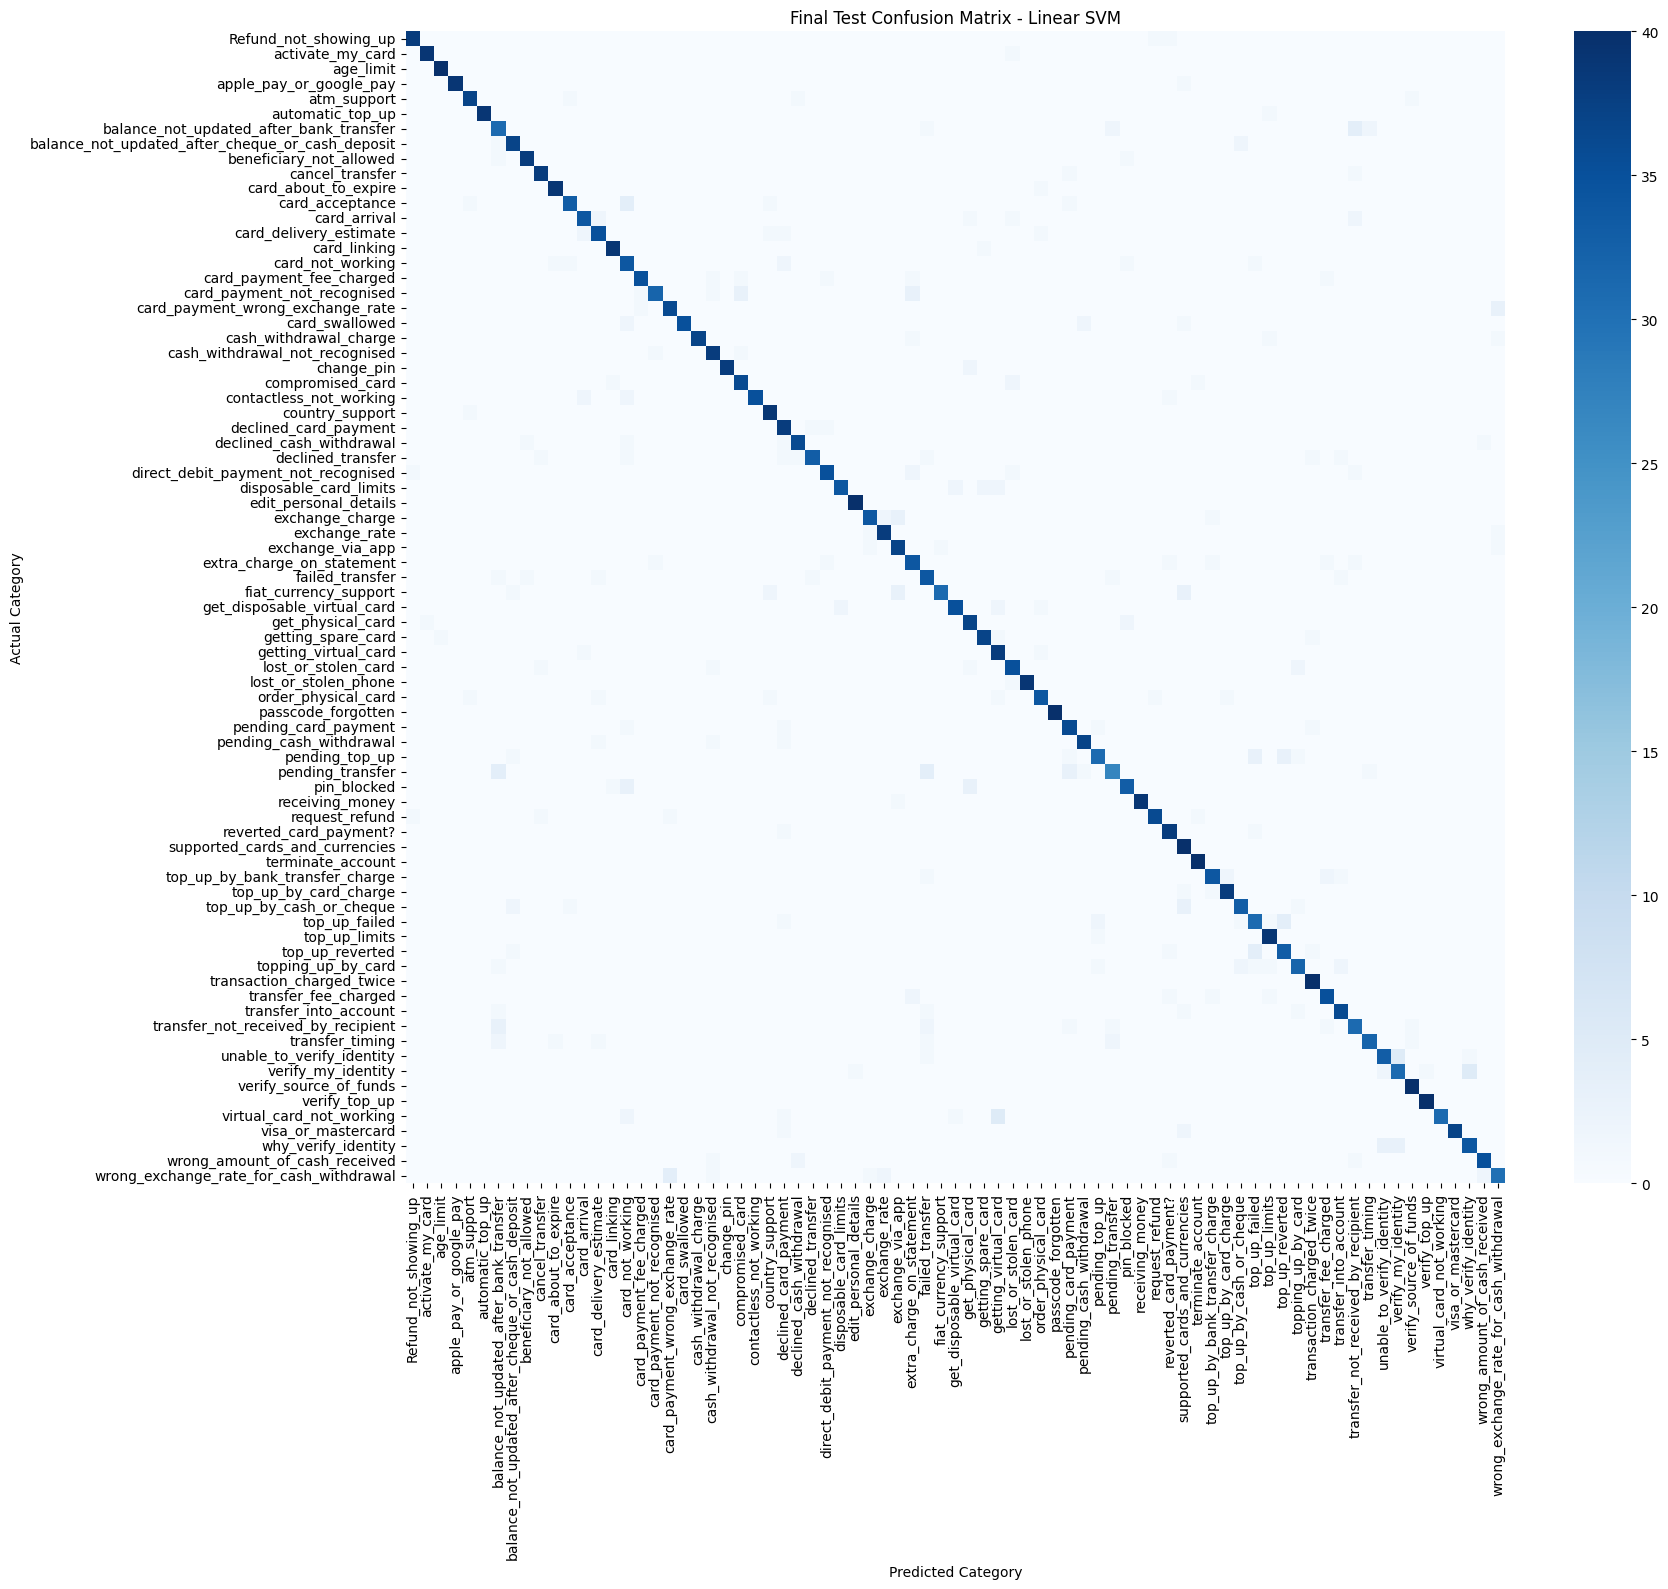

In [30]:
test_cm = confusion_matrix(
    y_test,
    final_pred,
    labels=sorted(y.unique())
)

plt.figure(figsize=(18, 16))

sns.heatmap(
    test_cm,
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title(f"Final Test Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

In [31]:
model_package = {
    "model": final_model,
    "vectorizer": final_tfidf,
    "model_name": best_model_name,
    "classes": sorted(y.unique())
}

joblib.dump(
    model_package,
    "support_query_router.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [32]:
sample_queries = [
    "I forgot my PIN",
    "My card has not arrived yet",
    "Why was my card payment declined?",
    "I want to cancel my transfer",
    "Someone stole my card",
    "I was charged twice for the same transaction",
    "How can I get a refund?"
]

clean_queries = [
    clean_text(q)
    for q in sample_queries
]

query_vectors = final_tfidf.transform(clean_queries)

predictions = final_model.predict(query_vectors)

for query, prediction in zip(sample_queries, predictions):
    print("Query:", query)
    print("Predicted Category:", prediction)
    print("-" * 70)

Query: I forgot my PIN
Predicted Category: pin_blocked
----------------------------------------------------------------------
Query: My card has not arrived yet
Predicted Category: transfer_not_received_by_recipient
----------------------------------------------------------------------
Query: Why was my card payment declined?
Predicted Category: declined_card_payment
----------------------------------------------------------------------
Query: I want to cancel my transfer
Predicted Category: cancel_transfer
----------------------------------------------------------------------
Query: Someone stole my card
Predicted Category: lost_or_stolen_card
----------------------------------------------------------------------
Query: I was charged twice for the same transaction
Predicted Category: transaction_charged_twice
----------------------------------------------------------------------
Query: How can I get a refund?
Predicted Category: request_refund
-----------------------------------------